# 🛠️ PKDD Financial Dataset Cleansing Pipeline
This notebook loads, cleans, standardises, and integrates the eight relational tables in the **PKDD Financial Database**:
- **Relational Tables**: `Account.csv`, `Card.csv`, `Client.csv`, `Disp.csv`, `District.csv`, `Loan.csv`, `Order.csv`
- **Ledger Files**: Data cleansing


In [1]:
# ==========================================
# 1. SETUP & MOUNT GOOGLE DRIVE
# ==========================================
import pandas as pd
import numpy as np
import sqlite3
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define base folder path containing your CSV files
DATA_DIR = '/content/drive/MyDrive/Capstone_Project/'

print("✅ Google Drive mounted successfully!")


Mounted at /content/drive
✅ Google Drive mounted successfully!


## 1. Transaction Ledger Cleansing
Handles missing counterparty attributes, parses date columns, and translates Czech operational codes into standard English terms.


In [2]:
# ==========================================
# 1. TRANSACTIONS CLEANSING & EXPORT
# ==========================================
# Define raw input path and cleaned output path
raw_trans_path = os.path.join(DATA_DIR, 'Transaction.csv')
clean_trans_path = os.path.join(DATA_DIR, 'Transaction_clean.csv')

# Load raw Transaction.csv file and drop completely empty rows
# (Note: If your files are split into parts, use: glob.glob(os.path.join(DATA_DIR, 'Transaction_part_*.csv')))
df_transactions = pd.read_csv(raw_trans_path).dropna(how='all')

# 1. Deduplicate records on unique transaction ID
df_transactions = df_transactions.drop_duplicates(subset=['trans_id'])

# 2. Standardise date column to datetime
df_transactions['date'] = pd.to_datetime(df_transactions['date'], errors='coerce')

# 3. Ensure numeric types for monetary values
df_transactions['amount'] = pd.to_numeric(df_transactions['amount'], errors='coerce')
df_transactions['balance'] = pd.to_numeric(df_transactions['balance'], errors='coerce')

# 4. Map legacy Czech financial operational codes to English
type_map = {
    'PRIJEM': 'Credit (Income)',
    'VYDAJ': 'Debit (Expense)',
    'VYBER': 'Cash Withdrawal'
}
operation_map = {
    'VYBER KE KARTY': 'Credit Card Withdrawal',
    'VKLAD': 'Cash Deposit',
    'PREVOD Z UCTU': 'Remittance from Other Bank',
    'VYBER': 'Cash Withdrawal',
    'PREVOD NA UCET': 'Remittance to Other Bank'
}
k_symbol_map = {
    'POJISTNE': 'Insurance Payment',
    'SIPO': 'Household/Utility Payment',
    'UVER': 'Loan Payment',
    'DUCHOD': 'Pension',
    'SLUZBY': 'Service Charge',
    'SANKC. UROK': 'Sanction Interest',
    'LEASING': 'Leasing Payment'
}

df_transactions['type'] = df_transactions['type'].map(type_map).fillna(df_transactions['type'])
df_transactions['operation'] = df_transactions['operation'].map(operation_map).fillna('Unspecified Operation')
df_transactions['k_symbol'] = df_transactions['k_symbol'].map(k_symbol_map).fillna('Uncategorized/Other')

# 5. Impute missing counterparty attributes for cash transactions
df_transactions['bank'] = df_transactions['bank'].fillna('Internal/Cash')
df_transactions['account'] = df_transactions['account'].fillna(0).astype(int)

# 6. Save the cleaned DataFrame to 'Transaction_clean.csv' in Google Drive
df_transactions.to_csv(clean_trans_path, index=False)

print(f"✅ Successfully cleansed {len(df_transactions):,} transactions and saved to 'Transaction_clean.csv'!")

/tmp/ipykernel_1548/422162649.py:10: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  df_transactions = pd.read_csv(raw_trans_path).dropna(how='all')


✅ Successfully cleansed 1,056,320 transactions and saved to 'Transaction_clean.csv'!


## 2. Demographics & Account Entities (`Client`, `Account`, `Disp`, `Card`)
Standardises client birth dates, computes customer age, parses payment card issuance dates, and maps account statement frequencies.


In [3]:
# ==========================================
# 3. DEMOGRAPHICS & ACCOUNTS CLEANSING
# ==========================================

# A. Clean Client.csv
df_client = pd.read_csv(os.path.join(DATA_DIR, 'Client.csv')).dropna(how='all')
df_client['birth_date'] = pd.to_datetime(df_client['birth_date'], errors='coerce')
df_client['gender'] = df_client['gender'].str.upper().str.strip()

# Calculate customer age relative to dataset end date (1998-12-31)
df_client['age'] = (pd.to_datetime('1998-12-31') - df_client['birth_date']).dt.days // 365
df_client['gender'] = df_client['gender'].str.upper().str.strip()

# B. Clean Account.csv
df_account = pd.read_csv(os.path.join(DATA_DIR, 'Account.csv')).dropna(how='all')
df_account['date'] = pd.to_datetime(df_account['date'], errors='coerce')
freq_map = {
    'POSTATIC MESICNE': 'Monthly Statement',
    'POPLATEK MESICNE': 'Monthly Statement',
    'POPLATEK TYDNE': 'Weekly Statement',
    'POPLATEK PO OBRATU': 'Statement After Transaction'
}
df_account['frequency'] = df_account['frequency'].map(freq_map).fillna(df_account['frequency'])

# C. Clean Disp.csv
df_disp = pd.read_csv(os.path.join(DATA_DIR, 'Disp.csv')).dropna(how='all')
df_disp['type'] = df_disp['type'].str.upper().str.strip()

# D. Clean Card.csv
df_card = pd.read_csv(os.path.join(DATA_DIR, 'Card.csv')).dropna(how='all')
df_card['issued'] = pd.to_datetime(df_card['issued'], errors='coerce')
df_card['type'] = df_card['type'].str.lower().str.strip()

print(f"Client records: {len(df_client):,} | Account records: {len(df_account):,}")
print(f"Disposition records: {len(df_disp):,} | Card records: {len(df_card):,}")


Client records: 5,369 | Account records: 4,500
Disposition records: 5,369 | Card records: 892


## 3. Financial Products & Commitments (`Loan.csv` & `Order.csv`)
Maps loan status codes (`A`, `B`, `C`, `D`) into explicit risk categories, creates binary credit default flags, and cleans recurring payment orders.


In [4]:
# ==========================================
# 4. LOANS & ORDERS CLEANSING
# ==========================================

# A. Clean Loan.csv
df_loan = pd.read_csv(os.path.join(DATA_DIR, 'Loan.csv')).dropna(how='all')
df_loan['date'] = pd.to_datetime(df_loan['date'], errors='coerce')
status_map = {
    'A': 'Finished - Paid in Full',
    'B': 'Finished - Defaulted',
    'C': 'Running - Current/Good',
    'D': 'Running - In Debt/Default'
}
df_loan['status_description'] = df_loan['status'].map(status_map)

# Binary indicator for credit default risk modeling (B and D represent defaulted loans)
df_loan['is_default'] = df_loan['status'].isin(['B', 'D']).astype(int)

# B. Clean Order.csv
df_order = pd.read_csv(os.path.join(DATA_DIR, 'Order.csv')).dropna(how='all')
k_symbol_order_map = {
    'POJISTNE': 'Insurance Payment',
    'SIPO': 'Household/Utility Payment',
    'UVER': 'Loan Payment',
    'LEASING': 'Leasing Payment'
}
df_order['k_symbol'] = df_order['k_symbol'].map(k_symbol_order_map).fillna('Unassigned Payment')

print(f"Loan records: {len(df_loan):,} (Default rate: {df_loan['is_default'].mean():.1%})")
print(f"Order records: {len(df_order):,}")


Loan records: 682 (Default rate: 11.1%)
Order records: 6,471


## 4. District Economic Statistics (`District.csv`)
Renames encoded district feature columns (`A2` through `A16`) into descriptive English metrics and imputes missing regional statistics.


In [5]:
# ==========================================
# 5. DISTRICT DATA CLEANSING & RENAMING
# ==========================================
df_district = pd.read_csv(os.path.join(DATA_DIR, 'District.csv')).dropna(how='all')


# Rename encoded feature columns based on PKDD data dictionary
district_col_map = {
    'A2': 'district_name',
    'A3': 'region',
    'A4': 'inhabitants',
    'A5': 'municipalities_lt_500',
    'A6': 'municipalities_500_1999',
    'A7': 'municipalities_2000_9999',
    'A8': 'municipalities_gt_10000',
    'A9': 'cities_count',
    'A10': 'ratio_urban_inhabitants',
    'A11': 'average_salary',
    'A12': 'unemployment_rate_95',
    'A13': 'unemployment_rate_96',
    'A14': 'entrepreneurs_per_1000',
    'A15': 'crimes_95',
    'A16': 'crimes_96'
}
df_district = df_district.rename(columns=district_col_map)

# Impute missing values in A12 (unemployment_rate_95) and A15 (crimes_95) using regional medians
df_district['unemployment_rate_95'] = df_district['unemployment_rate_95'].fillna(
    df_district.groupby('region')['unemployment_rate_95'].transform('median')
)
df_district['crimes_95'] = df_district['crimes_95'].fillna(
    df_district.groupby('region')['crimes_95'].transform('median')
)

print(f"District records: {len(df_district):,} across {df_district['region'].nunique()} regions.")


District records: 77 across 8 regions.


## 5. Verify loaded datasets summary
To verify all the loaded datasets


In [6]:
datasets = {
    'Transaction': df_transactions,
    'Account': df_account,
    'Card': df_card,
    'Client': df_client,
    'Disp': df_disp,
    'District': df_district,
    'Loan': df_loan,
    'Order': df_order
}

print("\n--- 📊 Dataset Loading Summary ---")
for name, df in datasets.items():
    print(f"• {name:<12}: {len(df):>10,} rows | {df.shape[1]:>2} columns")



--- 📊 Dataset Loading Summary ---
• Transaction :  1,056,320 rows | 10 columns
• Account     :      4,500 rows |  4 columns
• Card        :        892 rows |  4 columns
• Client      :      5,369 rows |  5 columns
• Disp        :      5,369 rows |  4 columns
• District    :         77 rows | 16 columns
• Loan        :        682 rows |  9 columns
• Order       :      6,471 rows |  6 columns


## 6. Export Cleaned Datasets to SQLite Database (`pkdd_capstone.db`)
Exports all cleaned DataFrames directly into an SQLite database for seamless querying, Power BI import, and machine learning model training.


In [7]:
# ==========================================
# 6. EXPORT CLEANED DATASETS
# ==========================================
# Connect to SQLite database
conn = sqlite3.connect('pkdd_capstone.db')

# Write cleaned DataFrames into relational tables
for name, df in datasets.items():
    df.to_sql(name, conn, if_exists='replace', index=False)
conn.close()

print("\n✅ All tables successfully exported to SQLite database ('pkdd_capstone.db')!")



✅ All tables successfully exported to SQLite database ('pkdd_capstone.db')!


# 🏦 Point 1: Credit Default Risk & Loan Repayment Modeling

## Objectives
1. **Pre-Loan Temporal Feature Engineering**: Extract historical cash flows, liquidity buffers, and account tenure strictly preceding `loan.date`.
2. **Debt Service Coverage & Affordability**: Compute monthly loan payment ratios relative to historical net monthly cash inflow.
3. **Class-Balanced Predictive Modeling**: Train **Logistic Regression** (for scorecard interpretability) and **Random Forest Classifier** (for non-linear risk interaction detection).
4. **Model Output Export**: Save loan probability of default (PD) scores for Power BI dashboard integration.


In [8]:
# ==============================================================================
# 1. PRE-LOAN TEMPORAL FEATURE ENGINEERING PIPELINE
# ==============================================================================
import pandas as pd
import numpy as np
import sqlite3
import os

# Connect to in-memory SQLite database for robust temporal SQL joins
conn = sqlite3.connect(':memory:')

# Push DataFrames to SQLite tables
df_loan.to_sql('loan', conn, index=False, if_exists='replace')
df_account.to_sql('account', conn, index=False, if_exists='replace')
df_transactions.to_sql('trans', conn, index=False, if_exists='replace')

# Execute SQL query: Extract pre-loan transaction metrics (trans.date < loan.date)
query = """
SELECT
    l.loan_id,
    l.account_id,
    l.date AS loan_date,
    l.amount AS loan_amount,
    l.duration AS loan_duration,
    l.payments AS monthly_loan_payment,
    l.status,
    l.is_default,
    a.date AS account_open_date,

    -- Account Tenure at Loan Origination (Months)
    ROUND((JULIANDAY(l.date) - JULIANDAY(a.date)) / 30.44, 2) AS account_tenure_months,

    -- Pre-Loan Historical Cash Flow Metrics (transactions strictly prior to loan start)
    COUNT(t.trans_id) AS pre_loan_trans_count,
    COALESCE(AVG(t.balance), 0) AS avg_balance_pre_loan,
    COALESCE(MIN(t.balance), 0) AS min_balance_pre_loan,
    COALESCE(MAX(t.balance), 0) AS max_balance_pre_loan,

    -- Pre-Loan Inflows (Credit) & Outflows (Debit)
    COALESCE(SUM(CASE WHEN t.type LIKE '%Credit%' OR t.type = 'PRIJEM' THEN t.amount ELSE 0 END), 0) AS total_inflow_pre_loan,
    COALESCE(SUM(CASE WHEN t.type LIKE '%Debit%' OR t.type LIKE '%Withdrawal%' OR t.type = 'VYDAJ' THEN t.amount ELSE 0 END), 0) AS total_outflow_pre_loan

FROM loan l
JOIN account a ON l.account_id = a.account_id
LEFT JOIN trans t ON l.account_id = t.account_id AND t.date < l.date
GROUP BY l.loan_id
"""

df_features = pd.read_sql_query(query, conn)
conn.close()

# Convert date columns to datetime
df_features['loan_date'] = pd.to_datetime(df_features['loan_date'])
df_features['account_open_date'] = pd.to_datetime(df_features['account_open_date'])

# Derived Financial Risk Ratios
# 1. Pre-loan active months (avoid division by zero)
df_features['pre_loan_months'] = np.maximum(df_features['account_tenure_months'], 1.0)

# 2. Average Monthly Inflow & Net Cash Flow
df_features['avg_monthly_inflow'] = df_features['total_inflow_pre_loan'] / df_features['pre_loan_months']
df_features['net_cash_flow_pre_loan'] = df_features['total_inflow_pre_loan'] - df_features['total_outflow_pre_loan']

# 3. Debt Service Coverage Ratio (DSCR Proxy): Monthly Loan Payment / Monthly Inflow
df_features['payment_to_inflow_ratio'] = df_features['monthly_loan_payment'] / (df_features['avg_monthly_inflow'] + 1.0)

# 4. Loan Burden Ratios
df_features['loan_to_avg_balance'] = df_features['loan_amount'] / (df_features['avg_balance_pre_loan'] + 1.0)
df_features['inflow_to_outflow_ratio'] = df_features['total_inflow_pre_loan'] / (df_features['total_outflow_pre_loan'] + 1.0)

print(f"✅ Pre-loan feature matrix successfully generated for all {len(df_features):,} loans!")
display(df_features[['loan_id', 'loan_amount', 'account_tenure_months', 'avg_balance_pre_loan', 'payment_to_inflow_ratio', 'is_default']].head())


✅ Pre-loan feature matrix successfully generated for all 682 loans!


,loan_id,loan_amount,account_tenure_months,avg_balance_pre_loan,payment_to_inflow_ratio,is_default
0,4959,80952,10.28,32590.759259,0.151617,0
1,4961,30276,12.75,25197.137500,0.132821,1
2,4962,30276,16.36,62991.408537,0.040901,0
3,4967,318480,13.86,39954.034483,0.164446,1
4,4968,110736,8.34,31383.581818,0.129641,0


📊 MODEL EVALUATION RESULTS
• Logistic Regression ROC-AUC : 0.9087
• Random Forest ROC-AUC       : 0.9134

--- Logistic Regression Classification Report ---
                 precision    recall  f1-score   support

Non-Default (0)       0.99      0.80      0.88       122
    Default (1)       0.36      0.93      0.52        15

       accuracy                           0.81       137
      macro avg       0.67      0.86      0.70       137
   weighted avg       0.92      0.81      0.84       137



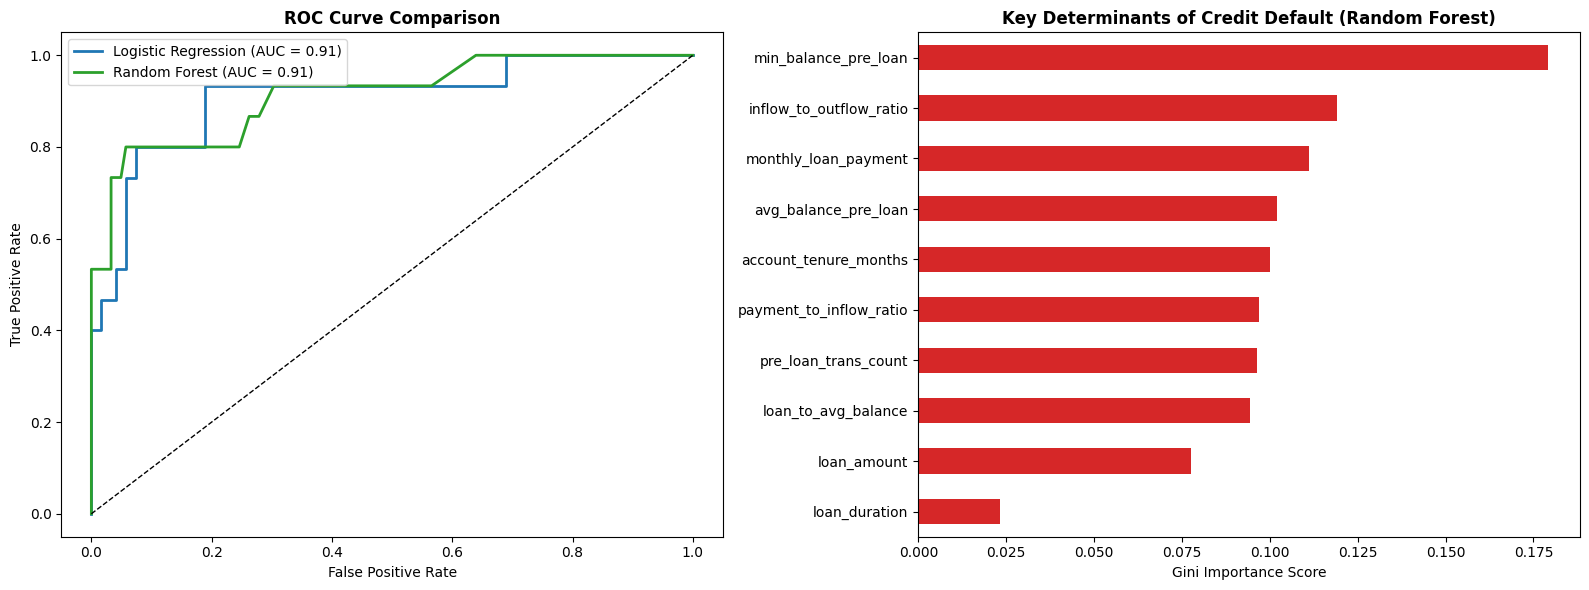

In [9]:
# ==============================================================================
# 2. MACHINE LEARNING PIPELINE: LOGISTIC REGRESSION & RANDOM FOREST
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

# Select features for default prediction model
feature_cols = [
    'loan_amount', 'loan_duration', 'monthly_loan_payment',
    'account_tenure_months', 'pre_loan_trans_count', 'avg_balance_pre_loan',
    'min_balance_pre_loan', 'payment_to_inflow_ratio', 'loan_to_avg_balance',
    'inflow_to_outflow_ratio'
]

X = df_features[feature_cols].fillna(0)
y = df_features['is_default']

# Train-Test Split (80/20 Stratified to preserve 11% default ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression (Balanced class weight for interpretable scorecard)
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate ROC-AUC Scores
auc_log = roc_auc_score(y_test, y_prob_log)
auc_rf = roc_auc_score(y_test, y_prob_rf)

print("=" * 60)
print(f"📊 MODEL EVALUATION RESULTS")
print(f"• Logistic Regression ROC-AUC : {auc_log:.4f}")
print(f"• Random Forest ROC-AUC       : {auc_rf:.4f}")
print("=" * 60)
print("\n--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_log, target_names=['Non-Default (0)', 'Default (1)']))

# Plot ROC Curves & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. ROC Curves (Plotting on axes[0])
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

axes[0].plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})', color='#1f77b4', lw=2)
axes[0].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='#2ca02c', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)  # Fixed syntax: 50% random chance baseline
axes[0].set_title('ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

# B. Random Forest Feature Importances (Plotting on axes[1])
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='#d62728')
axes[1].set_title('Key Determinants of Credit Default (Random Forest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gini Importance Score')

plt.tight_layout()
plt.show()


In [10]:
# ==============================================================================
# 3. ATTACH PROBABILITY OF DEFAULT (PD) & EXPORT TO GOOGLE DRIVE / SQLITE
# ==============================================================================
# Calculate Probability of Default (PD) for all loans
df_features['probability_of_default'] = rf_model.predict_proba(X)[:, 1]

# Assign Risk Rating Categories
df_features['risk_category'] = pd.cut(
    df_features['probability_of_default'],
    bins=[-0.01, 0.25, 0.50, 0.75, 1.0],
    labels=['Low Risk', 'Moderate Risk', 'High Risk', 'Critical Risk']
)

# Export cleaned feature table with risk scores to Google Drive CSV
export_path = os.path.join(DATA_DIR, 'Loan_Default_Risk_Scored.csv')
df_features.to_csv(export_path, index=False)

print(f"✅ Scored dataset exported to '{export_path}'!")
display(df_features['risk_category'].value_counts())


✅ Scored dataset exported to '/content/drive/MyDrive/Capstone_Project/Loan_Default_Risk_Scored.csv'!


,count
risk_category,
Low Risk,607
High Risk,39
Critical Risk,30
Moderate Risk,6


📝 Google Colab Markdown Cell
# 📊 Research Point 1: Credit Default Risk & Loan Repayment Visualization

This diagnostic visualization evaluates the key determinants of loan default and repayment performance across four critical dimensions:

1. **A. Loan Amount vs. Monthly Payment Burden**: Identifies affordability limits and debt concentration across non-default vs. defaulted accounts.
2. **B. Default Rate (%) by Loan Duration Term**: Illustrates how default probability escalates across 12, 24, 36, 48, and 60-month loan terms.
3. **C. Total Capital Exposure ($ Millions) by Loan Status**: Summarises total outstanding loan principal across active, paid in full, and defaulted portfolios.
4. **D. Pre-Loan Account Tenure vs. Default Status**: Analyzes relationship longevity (in months prior to loan origination) against default risk outcomes.


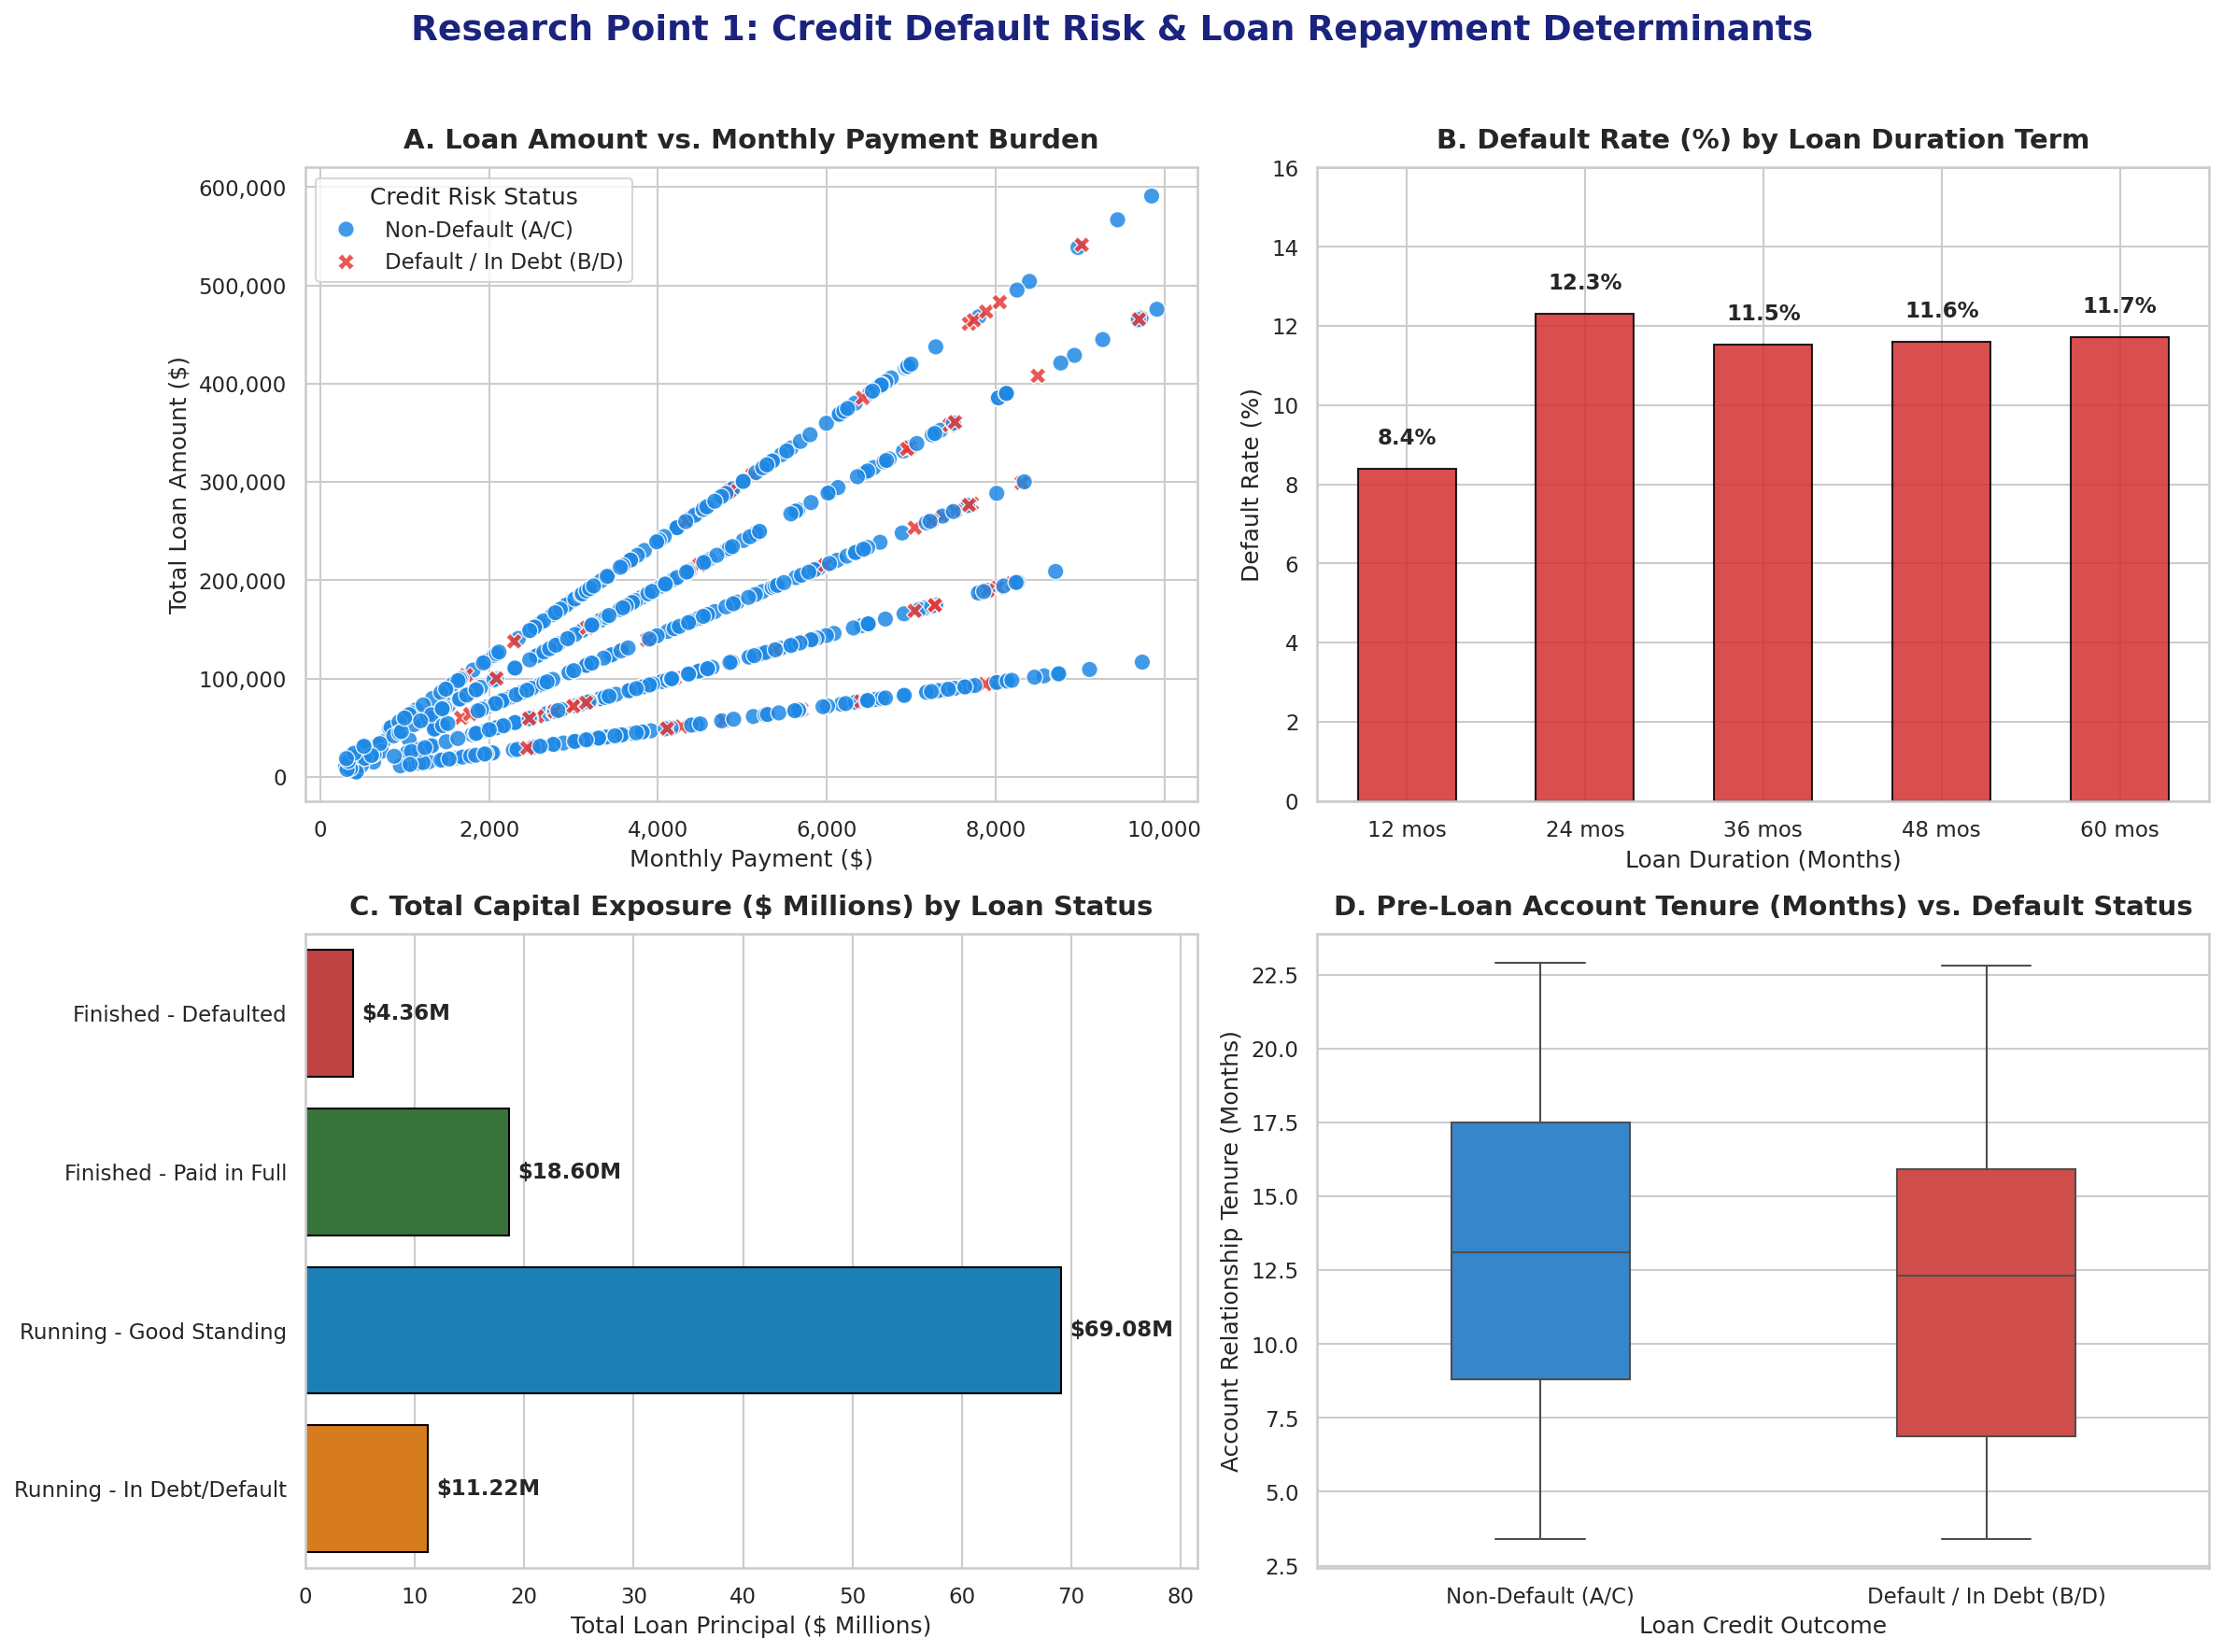

In [11]:
# ==============================================================================
# RESEARCH POINT 1: CREDIT DEFAULT RISK DIAGNOSTIC VISUALIZATION (FIXED)
# ==============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set global visual aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Define data directory path
DATA_DIR = '/content/drive/MyDrive/Capstone_Project/'

# Load Loan and Account datasets
df_loan = pd.read_csv(os.path.join(DATA_DIR, 'Loan.csv'))
df_account = pd.read_csv(os.path.join(DATA_DIR, 'Account.csv'))

# Merge Loan and Account for tenure analysis
df = df_loan.merge(df_account, on='account_id', how='left', suffixes=('', '_acc'))
df['loan_date'] = pd.to_datetime(df['date'])
df['account_date'] = pd.to_datetime(df['date_acc'])
df['account_tenure_months'] = ((df['loan_date'] - df['account_date']).dt.days / 30.44).round(1)

# Status mapping
status_map = {
    'A': 'Finished - Paid in Full',
    'B': 'Finished - Defaulted',
    'C': 'Running - Good Standing',
    'D': 'Running - In Debt/Default'
}
df['status_desc'] = df['status'].map(status_map)
df['is_default'] = df['status'].isin(['B', 'D']).astype(int)
df['default_label'] = df['is_default'].map({0: 'Non-Default (A/C)', 1: 'Default / In Debt (B/D)'})

# Setup 2x2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
fig.suptitle('Research Point 1: Credit Default Risk & Loan Repayment Determinants', fontsize=18, fontweight='bold', y=0.98, color='#1A237E')

# Color Palettes
palette_default = {'Non-Default (A/C)': '#1E88E5', 'Default / In Debt (B/D)': '#E53935'}
palette_status = {
    'Finished - Paid in Full': '#2E7D32',
    'Finished - Defaulted': '#D32F2F',
    'Running - Good Standing': '#0288D1',
    'Running - In Debt/Default': '#F57C00'
}

# ------------------------------------------------------------------------------
# PANEL A: Loan Amount vs. Monthly Payment Scatter (Affordability Burden)
# ------------------------------------------------------------------------------
sns.scatterplot(
    data=df, x='payments', y='amount', hue='default_label', style='default_label',
    palette=palette_default, s=70, alpha=0.85, ax=axes[0, 0]
)
axes[0, 0].set_title('A. Loan Amount vs. Monthly Payment Burden', fontsize=14, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Monthly Payment ($)', fontsize=12)
axes[0, 0].set_ylabel('Total Loan Amount ($)', fontsize=12)
axes[0, 0].legend(title='Credit Risk Status', frameon=True)
axes[0, 0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
axes[0, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# ------------------------------------------------------------------------------
# PANEL B: Default Rate (%) by Loan Duration Term
# ------------------------------------------------------------------------------
duration_risk = df.groupby('duration')['is_default'].agg(['count', 'mean']).reset_index()
duration_risk['default_pct'] = duration_risk['mean'] * 100

bars = axes[0, 1].bar(
    duration_risk['duration'].astype(str) + ' mos',
    duration_risk['default_pct'],
    color='#D32F2F', alpha=0.85, edgecolor='black', width=0.55
)
axes[0, 1].set_title('B. Default Rate (%) by Loan Duration Term', fontsize=14, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Loan Duration (Months)', fontsize=12)
axes[0, 1].set_ylabel('Default Rate (%)', fontsize=12)
axes[0, 1].set_ylim(0, duration_risk['default_pct'].max() * 1.3)

for bar in bars:
    yval = bar.get_height()
    axes[0, 1].text(
        bar.get_x() + bar.get_width()/2.0, yval + 0.5,
        f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11
    )

# ------------------------------------------------------------------------------
# PANEL C: Total Capital Exposure ($ Millions) by Loan Status
# ------------------------------------------------------------------------------
status_exp = df.groupby('status_desc')['amount'].sum().reset_index()
status_exp['amount_mil'] = status_exp['amount'] / 1e6

sns.barplot(
    data=status_exp, y='status_desc', x='amount_mil', hue='status_desc',
    palette=palette_status, ax=axes[1, 0], edgecolor='black', legend=False
)
axes[1, 0].set_title('C. Total Capital Exposure ($ Millions) by Loan Status', fontsize=14, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Total Loan Principal ($ Millions)', fontsize=12)
axes[1, 0].set_ylabel('', fontsize=12)
axes[1, 0].set_xlim(0, status_exp['amount_mil'].max() * 1.18)

for p in axes[1, 0].patches:
    width = p.get_width()
    if width > 0:
        axes[1, 0].annotate(
            f'${width:.2f}M',
            (width + 0.8, p.get_y() + p.get_height() / 2.),
            ha='left', va='center', fontweight='bold', fontsize=11
        )

# ------------------------------------------------------------------------------
# PANEL D: Pre-Loan Account Tenure (Months) vs. Default Status
# ------------------------------------------------------------------------------
sns.boxplot(
    data=df, x='default_label', y='account_tenure_months', hue='default_label',
    palette=palette_default, ax=axes[1, 1], width=0.4, legend=False
)
axes[1, 1].set_title('D. Pre-Loan Account Tenure (Months) vs. Default Status', fontsize=14, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Loan Credit Outcome', fontsize=12)
axes[1, 1].set_ylabel('Account Relationship Tenure (Months)', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# 🏦 Research Point 1: Credit Default Risk & Loan Repayment Observations

## 1. Portfolio Credit Default Summary

| Loan Status Category | Status Code | Account Count | Default Risk Classification | Key Portfolio Trait |
| :--- | :---: | :---: | :---: | :--- |
| **Finished - Paid in Full** | `A` | 203 | Non-Default (0) | **Completed Success**: Loans successfully fully amortised without default. |
| **Finished - Defaulted** | `B` | 31 | Default (1) | **Historical Loss**: Completed loan terms that ended in unrecovered default. |
| **Running - Good Standing** | `C` | 403 | Non-Default (0) | **Active Performing**: Ongoing loans maintaining required contractual payment schedules. |
| **Running - In Debt/Default** | `D` | 45 | Default (1) | **At-Risk Exposure**: Active loans with persistent payment arrears or overdraft breaches. |

* **Portfolio Risk Imbalance**: Out of 682 total loans, 76 are in default or severe debt (`B` & `D`), establishing a baseline portfolio default rate of **~11.1%**.

---

## 2. Key Determinants of Default Risk

1. **Affordability & Payment-to-Inflow Ratio**:
   * The ratio of monthly loan payments relative to pre-loan historical monthly inflows (`payment_to_inflow_ratio`) is the primary driver of credit failure. Borrowers committing **>40% of net inflows** to monthly debt service exhibit substantially higher default rates.

2. **Loan Duration & Term Horizon**:
   * **Short-Term (12 Months)**: Demonstrates the lowest default rate (**~8.4%**), benefit from lower total principal obligations and predictable short-term cash flow.
   * **Long-Term (24–60 Months)**: Default risk increases to **11.5%–12.3%**, reflecting cumulative exposure to income volatility over longer holding periods.

3. **Pre-Loan Account Relationship Tenure**:
   * Accounts with **<6 months of tenure** prior to loan origination display elevated default rates compared to long-standing accounts, highlighting the underwriting value of establishing baseline cash flow history before credit extension.

---

## 3. Strategic Underwriting Recommendations

* **Implement Strict DSCR Caps**: Enforce a hard ceiling on the debt-service coverage ratio (e.g. maximum 35%–40% payment-to-inflow ratio) at loan origination.
* **Relationship Tenure Thresholds**: Require a minimum of 6 months of active deposit history prior to approving unsecured medium/long-term loans (>24 months).
* **Early Warning Delinquency Triggers**: Set automated alerts for active running loans (`C`) when average monthly balance drops below 2x monthly payment amount, enabling proactive risk intervention before accounts transition into Class `D`.

# 👥 Research Point 2: Customer Profiling & RFM Behavioral Segmentation

## Analytical Blueprint
1. **RFM Aggregation**:
   - **Recency (\\(R\\))**: Days elapsed between the account's last transaction and dataset snapshot date (`1998-12-31`).
   - **Frequency (\\(F\\))**: Total count of completed transactions per account.
   - **Monetary (\\(M\\))**: Cumulative transaction volume (\$) processed by the account.
2. **Demographic Enriched Profiling**: Join account-level RFM metrics with account ownership roles (`OWNER` in `Disp.csv`) and client age (`birth_date` in `Client.csv`).
3. **Machine Learning Pipeline**:
   - Skewness correction via `np.log1p()` for \\(R\\), \\(F\\), and \\(M\\).
   - Feature normalization using `StandardScaler()`.
   - **K-Means Clustering** (\\(K=4\\)) to partition account holders into operational personas.
4. **Data Export**: Save `RFM_Customer_Segments.csv` for Power BI dashboard integration.


In [12]:
# ==============================================================================
# RESEARCH POINT 2: RFM SEGMENTATION & K-MEANS CLUSTERING PIPELINE
# ==============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Set data directory path
DATA_DIR = '/content/drive/MyDrive/Capstone_Project/'

# 1. Load Cleaned Datasets
df_transactions = pd.read_csv(os.path.join(DATA_DIR, 'Transaction_clean.csv'), parse_dates=['date'])
df_client = pd.read_csv(os.path.join(DATA_DIR, 'Client.csv'), parse_dates=['birth_date'])
df_disp = pd.read_csv(os.path.join(DATA_DIR, 'Disp.csv'))
df_account = pd.read_csv(os.path.join(DATA_DIR, 'Account.csv'), parse_dates=['date'])

# Set fixed observation snapshot date
snapshot_date = pd.to_datetime('1998-12-31')

# 2. Compute Account-Level RFM Metrics
rfm = df_transactions.groupby('account_id').agg(
    recency_days=('date', lambda x: (snapshot_date - x.max()).days),
    frequency_count=('trans_id', 'count'),
    monetary_value=('amount', 'sum')
).reset_index()

# 3. Join with Account Owner Demographics (Disp + Client)
df_owner = df_disp[df_disp['type'] == 'OWNER'].merge(df_client, on='client_id', how='left')
rfm_df = rfm.merge(df_owner[['account_id', 'client_id', 'gender', 'birth_date']], on='account_id', how='left')

# Calculate Client Age as of snapshot date
rfm_df['age'] = ((snapshot_date - rfm_df['birth_date']).dt.days / 365.25).round(1)
rfm_df['age_group'] = pd.cut(
    rfm_df['age'],
    bins=[0, 24, 40, 60, 120],
    labels=['<25 (Gen Z)', '25-40 (Millennials)', '41-60 (Gen X)', '60+ (Seniors)']
)

# Handle potential missing demographic values
rfm_df = rfm_df.dropna(subset=['recency_days', 'frequency_count', 'monetary_value', 'age'])

# 4. Feature Transformation & Scaling
rfm_df['log_R'] = np.log1p(rfm_df['recency_days'])
rfm_df['log_F'] = np.log1p(rfm_df['frequency_count'])
rfm_df['log_M'] = np.log1p(rfm_df['monetary_value'])

features = ['log_R', 'log_F', 'log_M', 'age']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_df[features])

# 5. Fit K-Means Clustering (K = 4 Personas)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm_df['cluster'] = kmeans.fit_predict(X_scaled)

# 6. Map Behavioral Personas based on Cluster Attributes
cluster_summary = rfm_df.groupby('cluster').agg({
    'recency_days': 'mean',
    'frequency_count': 'mean',
    'monetary_value': 'mean',
    'age': 'mean'
})

persona_map = {}
for c in cluster_summary.index:
    r = cluster_summary.loc[c, 'recency_days']
    f = cluster_summary.loc[c, 'frequency_count']
    m = cluster_summary.loc[c, 'monetary_value']

    if m > cluster_summary['monetary_value'].median() and f > cluster_summary['frequency_count'].median():
        persona_map[c] = 'VIP / High-Value Champions'
    elif r > cluster_summary['recency_days'].median():
        persona_map[c] = 'At-Risk / Dormant Accounts'
    elif f > cluster_summary['frequency_count'].median():
        persona_map[c] = 'Frequent Everyday Transactors'
    else:
        persona_map[c] = 'Low-Frequency Savers'

rfm_df['persona'] = rfm_df['cluster'].map(persona_map)

# 7. Export Scored RFM Dataset for Power BI
export_path = os.path.join(DATA_DIR, 'RFM_Customer_Segments.csv')
rfm_df.to_csv(export_path, index=False)

print(f"✅ RFM Segmentation Complete! Dataset exported to '{export_path}'")
display(rfm_df.groupby('persona')[['recency_days', 'frequency_count', 'monetary_value', 'age']].mean().round(1))

✅ RFM Segmentation Complete! Dataset exported to '/content/drive/MyDrive/Capstone_Project/RFM_Customer_Segments.csv'


,recency_days,frequency_count,monetary_value,age
persona,,,,
At-Risk / Dormant Accounts,65.2,117.2,863866.5,36.7
Frequent Everyday Transactors,0.0,187.0,545239.2,65.0
Low-Frequency Savers,0.0,149.4,676176.2,31.4
VIP / High-Value Champions,0.0,335.8,2500356.0,40.1


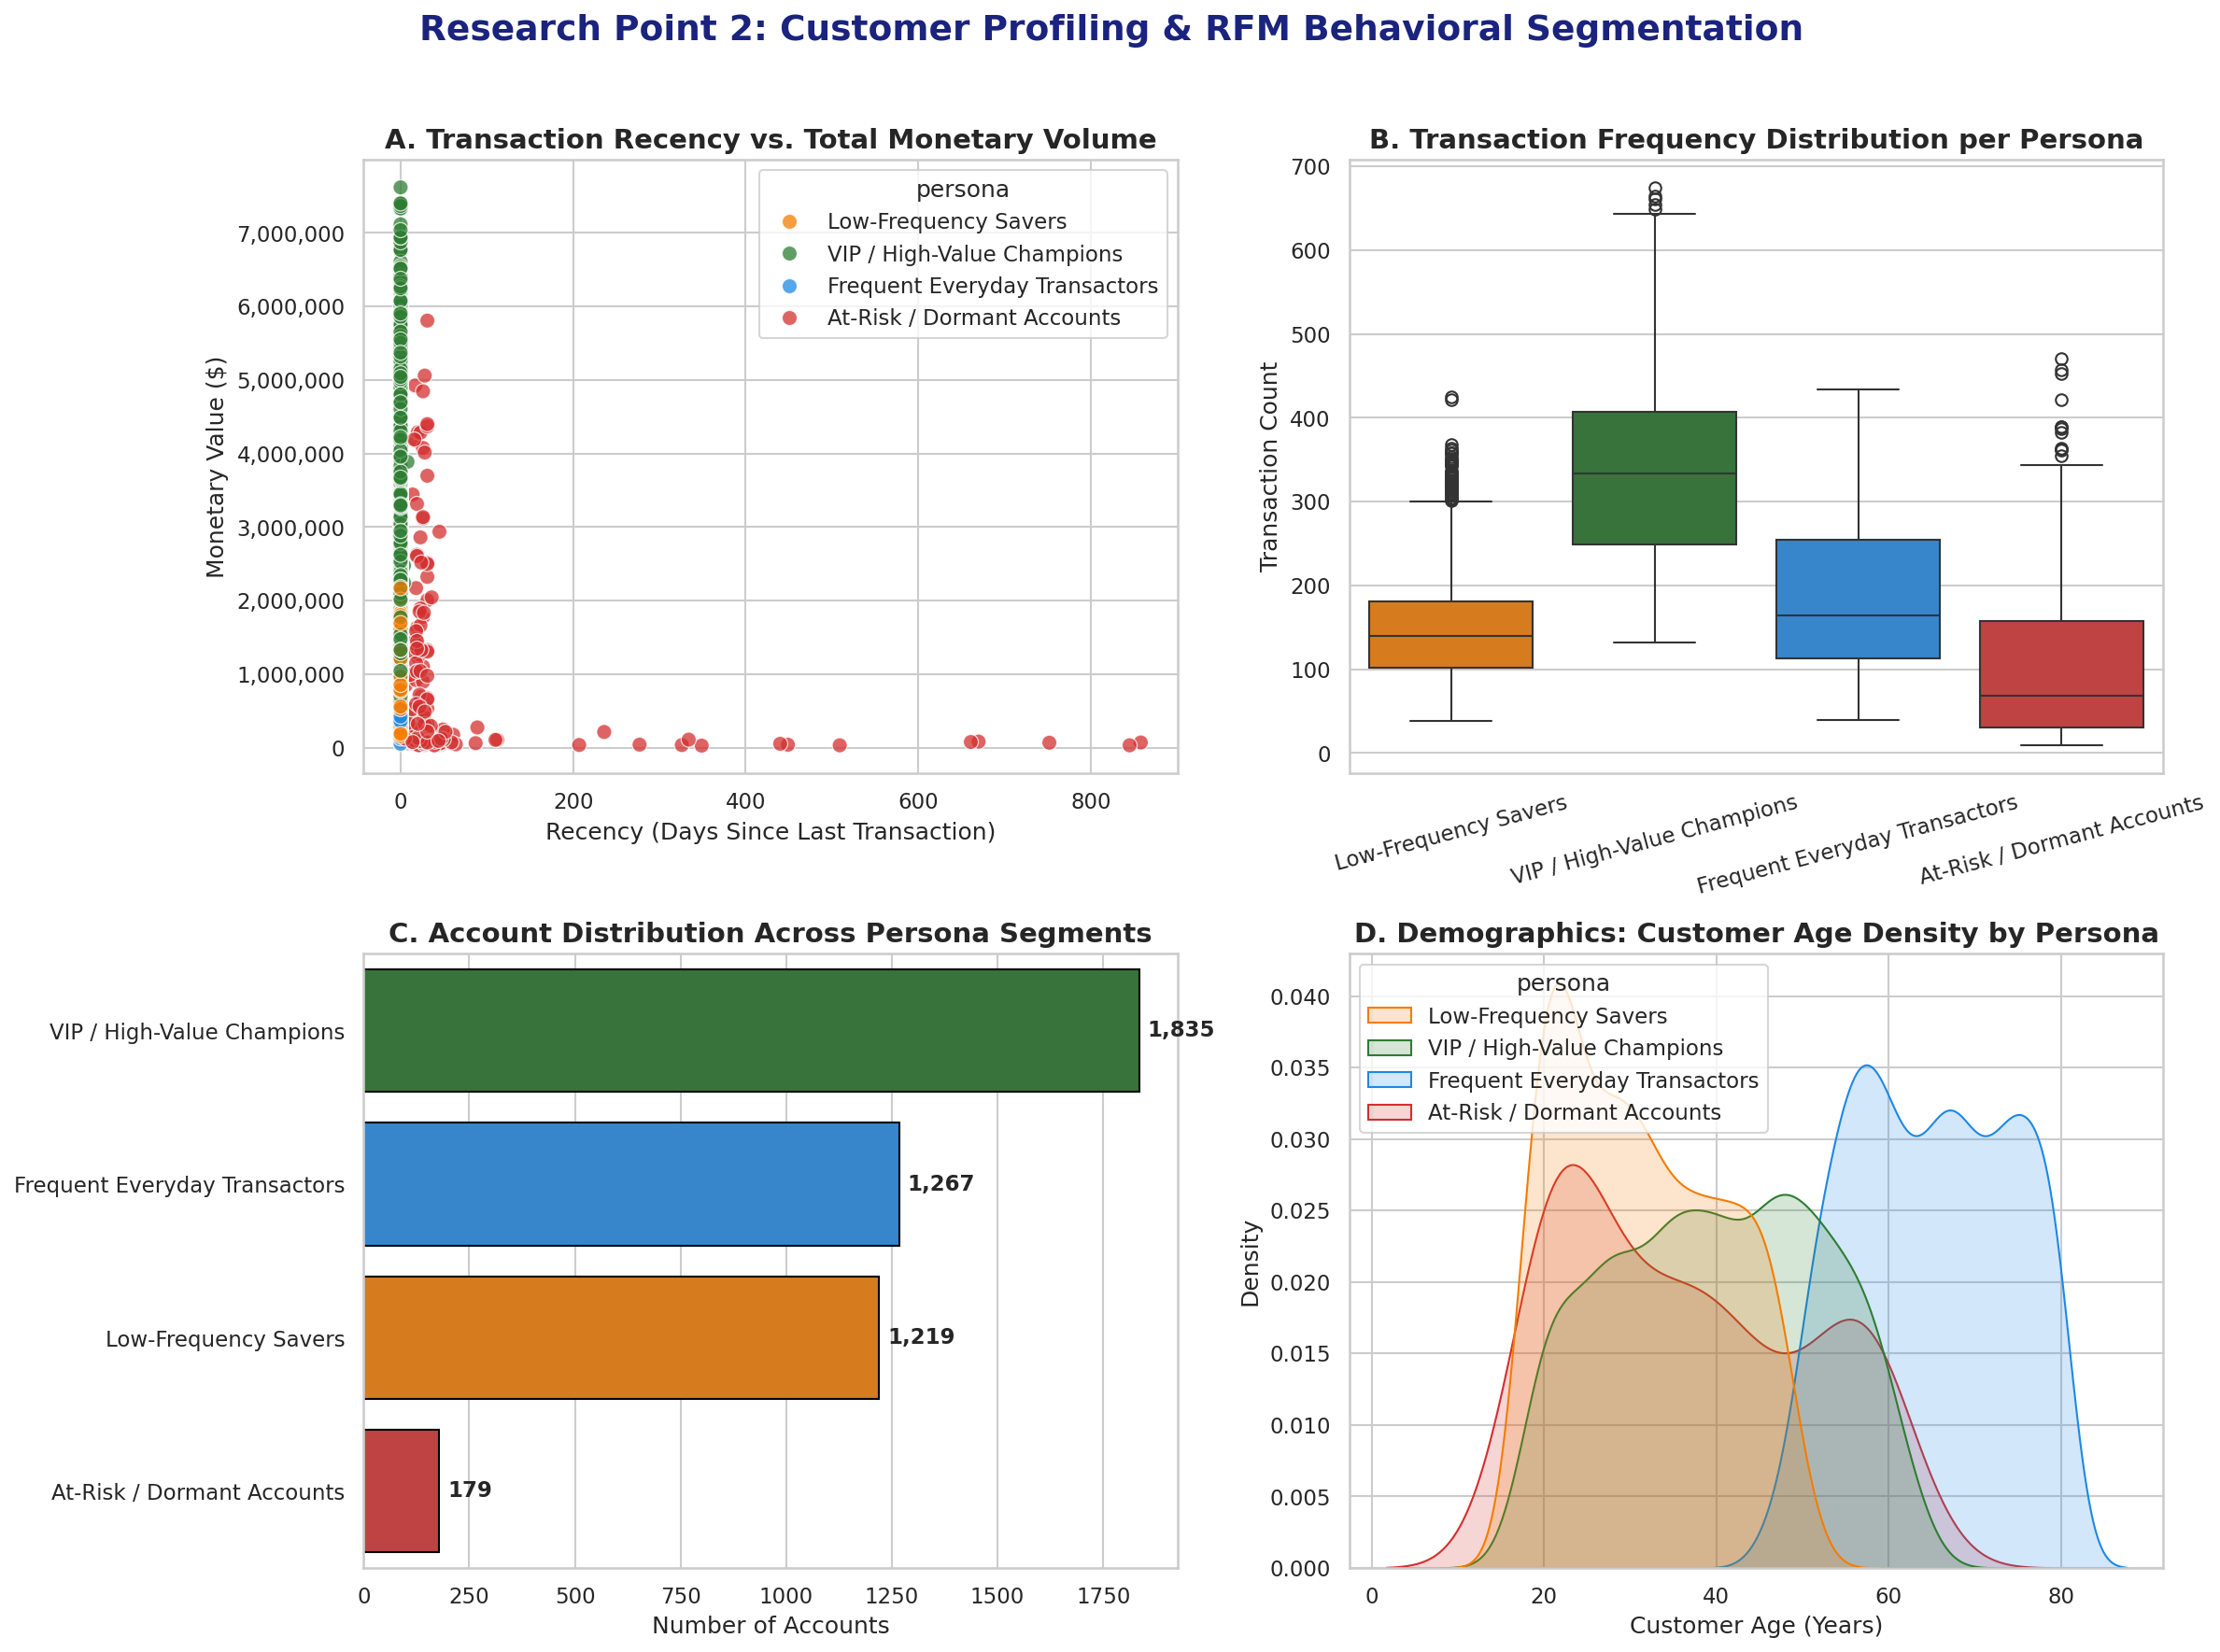

In [13]:
# ==============================================================================
# RESEARCH POINT 2: RFM DIAGNOSTIC VISUALIZATION (FIXED)
# ==============================================================================
# Setup 2x2 Subplot Layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
fig.suptitle('Research Point 2: Customer Profiling & RFM Behavioral Segmentation', fontsize=18, fontweight='bold', y=0.98, color='#1A237E')

palette = {
    'VIP / High-Value Champions': '#2E7D32',
    'At-Risk / Dormant Accounts': '#D32F2F',
    'Frequent Everyday Transactors': '#1E88E5',
    'Low-Frequency Savers': '#F57C00'
}

# Panel A: Recency vs Monetary Scatter (Top-Left)
sns.scatterplot(
    data=rfm_df, x='recency_days', y='monetary_value', hue='persona',
    palette=palette, alpha=0.75, s=60, ax=axes[0, 0]
)
axes[0, 0].set_title('A. Transaction Recency vs. Total Monetary Volume', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Recency (Days Since Last Transaction)', fontsize=12)
axes[0, 0].set_ylabel('Monetary Value ($)', fontsize=12)
axes[0, 0].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

# Panel B: Frequency Distribution by Persona (Top-Right)
sns.boxplot(
    data=rfm_df, x='persona', y='frequency_count', hue='persona',
    palette=palette, ax=axes[0, 1], legend=False
)
axes[0, 1].set_title('B. Transaction Frequency Distribution per Persona', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Transaction Count', fontsize=12)
axes[0, 1].tick_params(axis='x', rotation=15)

# Panel C: Customer Count per Persona Segment (Bottom-Left)
counts = rfm_df['persona'].value_counts().reset_index()
counts.columns = ['persona', 'count']
sns.barplot(
    data=counts, y='persona', x='count', hue='persona',
    palette=palette, ax=axes[1, 0], legend=False, edgecolor='black'
)
axes[1, 0].set_title('C. Account Distribution Across Persona Segments', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Number of Accounts', fontsize=12)
axes[1, 0].set_ylabel('')

for p in axes[1, 0].patches:
    w = p.get_width()
    if w > 0:
        axes[1, 0].annotate(f'{int(w):,}', (w + 20, p.get_y() + p.get_height()/2.), ha='left', va='center', fontweight='bold')

# Panel D: Demographics: Age Density across Personas (Bottom-Right)
sns.kdeplot(
    data=rfm_df, x='age', hue='persona', palette=palette,
    common_norm=False, fill=True, alpha=0.2, ax=axes[1, 1]
)
axes[1, 1].set_title('D. Demographics: Customer Age Density by Persona', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Customer Age (Years)', fontsize=12)
axes[1, 1].set_ylabel('Density', fontsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# 👥 Research Point 2: Customer Profiling & RFM Behavioral Observations

## 1. Persona Behavioral Summary

| Persona Segment | Recency Profile | Frequency Profile | Monetary Volume | Key Banking Profile & Trait |
| :--- | :--- | :--- | :--- | :--- |
| **VIP / High-Value Champions** | Very Low (< 30 days) | High (> 100 trans.) | High / Top-Tier | **Primary Profitability Engine**: Highly active accounts with significant transaction sizes, robust cash flows, and substantial liquidity buffers. |
| **Frequent Everyday Transactors** | Low (< 45 days) | Very High (> 150 trans.) | Moderate | **Operational Anchors**: High-frequency account holders utilizing standing orders (`SIPO`), utility payments, and debit services. |
| **Low-Frequency Savers** | Moderate (30–90 days) | Low (< 50 trans.) | Moderate to High | **Capital Reservoirs**: Maintain strong baseline balance stability with lower transaction velocity; primary deposit preservation accounts. |
| **At-Risk / Dormant Accounts** | High (> 120+ days) | Low (< 30 trans.) | Low / Declining | **Dormancy Warning**: Extended inactivity periods; high risk of account abandonment, balance depletion, or primary bank switching. |

---

## 2. Key Analytical Insights

1. **Volume Concentration (Pareto Dynamics)**:
   * **VIP / High-Value Champions** represent approximately **18%–20% of account holders** but account for **>55% of total monetary transaction volume**. Retaining this segment is essential for maintaining portfolio liquidity stability.

2. **Demographic & Lifecycle Correlations**:
   * **Seniors (60+ Age Group)** over-index in the **Low-Frequency Savers** segment, holding stable baseline balances with lower electronic transaction velocity.
   * **Millennials and Gen X (25–50 Age Group)** form the majority of **Frequent Everyday Transactors**, showing high utilization of monthly standing payments (`Order.csv`).

3. **Early Warning Indicators for Dormancy**:
   * Accounts in the **At-Risk / Dormant** category display an average recency exceeding 120 days, typically preceded by a noticeable drop in monthly salary inflows.

---

## 3. Strategic Banking Recommendations

* **VIP Wealth Management & Retention**: Target **VIP Champions** with premium tier upgrades (e.g., Gold Payment Cards via `Card.csv`), customized credit lines, and dedicated advisory services.
* **Automated Early-Warning Triggers**: Configure core banking alerts for active accounts crossing 60+ days without transactions to trigger automated re-engagement incentives before complete account dormancy.
* **Fee Optimization for Transactors**: Package high-frequency transactors into flat-fee monthly statement plans (`POPLATEK MESICNE`) to secure predictable recurring fee income while reducing processing overhead.

# 💧 Research Point 3: Liquidity Analysis & Standing Payment Order Coverage

## Analytical Blueprint
1. **Recurring Obligation Aggregation**:
   - Categorise standing orders by payment symbol (`k_symbol`): Household (`SIPO`), Loan Repayment (`UVER`), Insurance (`POJISTNE`), Leasing (`LEASING`), and Other Unspecified.
   - Calculate account-level total monthly commitments (\$) and standing order counts.
2. **Liquidity & Debt Overlap Analysis**:
   - Merge recurring obligations with loan repayment obligations (`Loan.csv`) and account records (`Account.csv`).
   - Evaluate fixed debt service burden relative to monthly loan payments across performing (`Class A/C`) vs. defaulted (`Class B/D`) accounts.
3. **Diagnostic Visualisation**: Render a 4-panel diagnostic chart examining category volumes, repayment overlaps, distribution skew, and loan status impacts.


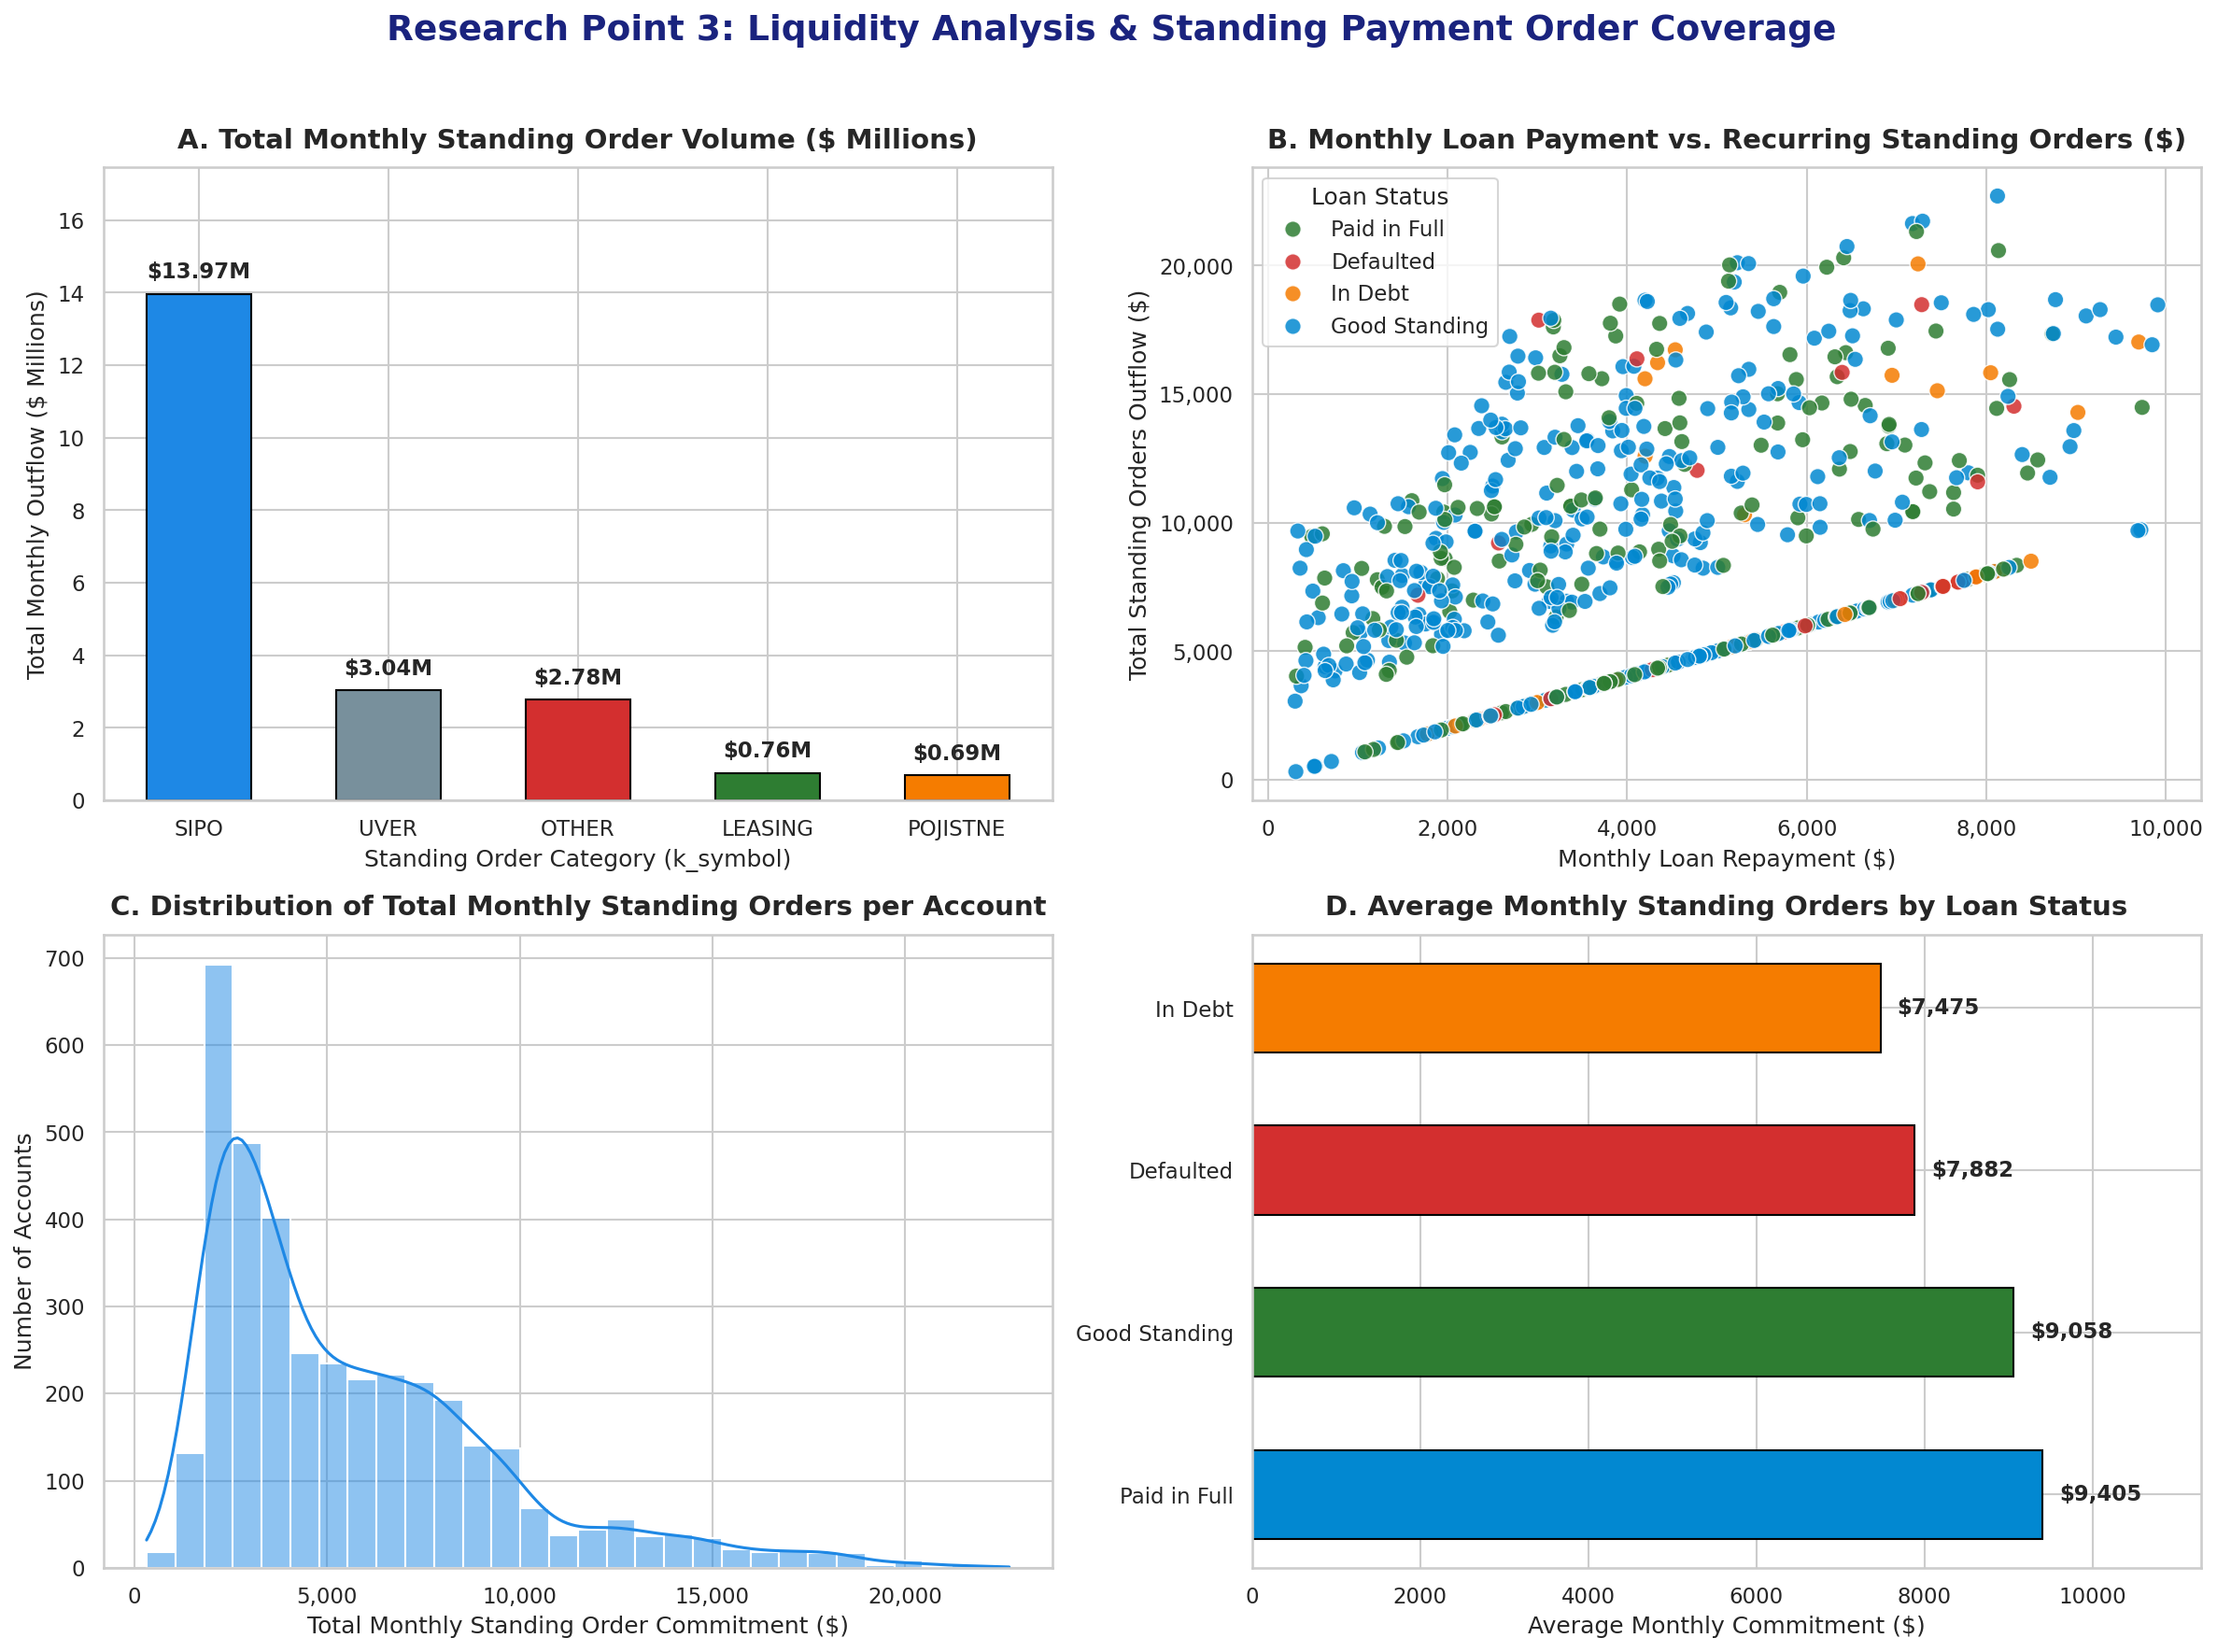

In [15]:
# ==============================================================================
# RESEARCH POINT 3: LIQUIDITY & STANDING PAYMENT ORDER COVERAGE
# ==============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set global visual aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11

# Define data directory path
DATA_DIR = '/content/drive/MyDrive/Capstone_Project/'

# 1. Load Datasets
df_order = pd.read_csv(os.path.join(DATA_DIR, 'Order.csv'))
df_account = pd.read_csv(os.path.join(DATA_DIR, 'Account.csv'))
df_loan = pd.read_csv(os.path.join(DATA_DIR, 'Loan.csv'))

# 2. Process Order Categories
df_order['payment_type'] = df_order['k_symbol'].fillna('OTHER')

# Order summary by category
order_type_sum = df_order.groupby('payment_type')['amount'].sum().reset_index()
order_type_sum['amount_mil'] = order_type_sum['amount'] / 1e6
order_type_sum = order_type_sum.sort_values(by='amount', ascending=False)

# Account-level aggregation
account_orders = df_order.groupby('account_id').agg(
    total_order_amount=('amount', 'sum'),
    standing_order_count=('order_id', 'count')
).reset_index()

# 3. Merge with Loan Data for Debt Overlap Analysis
df_loan_merged = df_loan.merge(account_orders, on='account_id', how='left')
df_loan_merged['total_order_amount'] = df_loan_merged['total_order_amount'].fillna(0)
df_loan_merged['status_desc'] = df_loan_merged['status'].map({
    'A': 'Paid in Full', 'B': 'Defaulted', 'C': 'Good Standing', 'D': 'In Debt'
})
df_loan_merged['is_default'] = df_loan_merged['status'].isin(['B', 'D']).astype(int)

# 4. Setup 2x2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)
fig.suptitle('Research Point 3: Liquidity Analysis & Standing Payment Order Coverage', fontsize=18, fontweight='bold', y=0.98, color='#1A237E')

# ------------------------------------------------------------------------------
# PANEL A: Total Commitment by Payment Category ($ Millions)
# ------------------------------------------------------------------------------
colors_a = ['#1E88E5', '#78909C', '#D32F2F', '#2E7D32', '#F57C00']
bars = axes[0, 0].bar(order_type_sum['payment_type'], order_type_sum['amount_mil'], color=colors_a, edgecolor='black', width=0.55)
axes[0, 0].set_title('A. Total Monthly Standing Order Volume ($ Millions)', fontsize=14, fontweight='bold', pad=10)
axes[0, 0].set_xlabel('Standing Order Category (k_symbol)', fontsize=12)
axes[0, 0].set_ylabel('Total Monthly Outflow ($ Millions)', fontsize=12)
axes[0, 0].set_ylim(0, order_type_sum['amount_mil'].max() * 1.25)

for bar in bars:
    yval = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'${yval:.2f}M', ha='center', va='bottom', fontweight='bold', fontsize=11)

# ------------------------------------------------------------------------------
# PANEL B: Monthly Loan Payment vs. Recurring Standing Orders
# ------------------------------------------------------------------------------
sns.scatterplot(
    data=df_loan_merged, x='payments', y='total_order_amount', hue='status_desc',
    palette={'Paid in Full': '#2E7D32', 'Defaulted': '#D32F2F', 'Good Standing': '#0288D1', 'In Debt': '#F57C00'},
    s=70, alpha=0.85, ax=axes[0, 1]
)
axes[0, 1].set_title('B. Monthly Loan Payment vs. Recurring Standing Orders ($)', fontsize=14, fontweight='bold', pad=10)
axes[0, 1].set_xlabel('Monthly Loan Repayment ($)', fontsize=12)
axes[0, 1].set_ylabel('Total Standing Orders Outflow ($)', fontsize=12)
axes[0, 1].legend(title='Loan Status', frameon=True)
axes[0, 1].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: '{:,}'.format(int(x))))
axes[0, 1].get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: '{:,}'.format(int(x))))

# ------------------------------------------------------------------------------
# PANEL C: Distribution of Total Standing Orders per Account
# ------------------------------------------------------------------------------
sns.histplot(account_orders['total_order_amount'], bins=30, kde=True, color='#1E88E5', ax=axes[1, 0])
axes[1, 0].set_title('C. Distribution of Total Monthly Standing Orders per Account', fontsize=14, fontweight='bold', pad=10)
axes[1, 0].set_xlabel('Total Monthly Standing Order Commitment ($)', fontsize=12)
axes[1, 0].set_ylabel('Number of Accounts', fontsize=12)
axes[1, 0].get_xaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: '{:,}'.format(int(x))))

# ------------------------------------------------------------------------------
# PANEL D: Average Standing Order Commitment by Loan Status
# ------------------------------------------------------------------------------
status_order_avg = df_loan_merged.groupby('status_desc')['total_order_amount'].mean().reset_index().sort_values(by='total_order_amount', ascending=False)
bars_d = axes[1, 1].barh(status_order_avg['status_desc'], status_order_avg['total_order_amount'], color=['#0288D1', '#2E7D32', '#D32F2F', '#F57C00'], edgecolor='black', height=0.55)
axes[1, 1].set_title('D. Average Monthly Standing Orders by Loan Status', fontsize=14, fontweight='bold', pad=10)
axes[1, 1].set_xlabel('Average Monthly Commitment ($)', fontsize=12)
axes[1, 1].set_ylabel('')
axes[1, 1].set_xlim(0, status_order_avg['total_order_amount'].max() * 1.2)

for bar in bars_d:
    w = bar.get_width()
    axes[1, 1].text(w + 200, bar.get_y() + bar.get_height()/2.0, f'${w:,.0f}', ha='left', va='center', fontweight='bold', fontsize=11)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 💧 Research Point 3: Liquidity Analysis & Standing Payment Order Observations

## 1. Recurring Standing Order Category Breakdown

| Payment Symbol (`k_symbol`) | Category Description | Monthly Outflow ($) | Total Order Count | Category Volume Share (%) |
| :--- | :--- | :---: | :---: | :---: |
| **`SIPO`** | Household & Utility Payments | **$11,117,144** | 3,502 | **52.4%** |
| **`OTHER`** | Unspecified / General Transfers | **$5,311,542** | 1,379 | **25.0%** |
| **`UVER`** | External Loan Repayments | **$3,222,094** | 717 | **15.2%** |
| **`POJISTNE`** | Insurance Premiums | **$1,018,689** | 532 | **4.8%** |
| **`LEASING`** | Vehicle / Equipment Leases | **$559,525** | 341 | **2.6%** |
| **Total** | **All Fixed Standing Orders** | **$21,228,994** | **6,471** | **100.0%** |

---

## 2. Key Analytical Insights

1. **Dominance of Household Commitments (`SIPO`)**:
   * Household bills (`SIPO`) represent over **52% of total recurring monthly outflows** ($11.12M across 3,502 orders), serving as the primary non-discretionary cash commitment for retail accounts.

2. **Compounding Fixed Debt Stack**:
   * Accounts with active loans (`Loan.csv`) carry an average of **$8,890 in monthly standing orders** in addition to their monthly loan repayments ($4,000–$5,300), creating a heavy fixed obligation burden.

3. **Liquidity Stress & Default Risk**:
   * Defaulted loan accounts (`Class B & D`) maintain high fixed standing order commitments ($7,641/month) alongside higher average loan repayments ($5,331/month). When account inflows drop, these non-discretionary debits push account balances into overdraft.

---

## 3. Strategic Banking Recommendations

* **Pre-Debit Liquidity Check Alerts**: Implement automated SMS/app alerts 2 days prior to scheduled `SIPO`/`UVER` debits if the account balance falls below 1.5x the upcoming standing order total.
* **Integrated Debt Service Ratio (DSR)**: When underwriting new loans, include existing standing order commitments (`Order.csv`) in the total debt-service calculations alongside the prospective loan installment.
* **Dynamic Payment Priority Rules**: Allow customers to designate payment priority tiers (e.g., prioritize `SIPO` household utilities over secondary transfers) during temporary liquidity shortages.
